# 二型中心裂纹：冷启动自适应源点优化与独立 BEM 参考

保留上传代码中的四分之一模型、上边及右边剪切加载和 KM–Williams 富集。全部核函数系数、富集系数及 KII 从零开始，与横纵源点外扩参数共同由 L-BFGS 优化。

参考值由同一 a、b、h、材料及边界条件下的直接边界元独立求解。原不含 h 的近似公式已删除。六个训练子图保留，KII 差异改为相对 BEM 的差异；BEM 不参与训练损失、初始化或最优状态选择。

**加载核对：本上传文件仍是上边和右边均施加剪应力。前一条要求的“上边剪切、右边自由”不是本文件的加载。若保持原轴线上约束而改为仅顶边剪切，允许的刚体转动对应非零外力矩，需先补充承担力矩的支承，再重新设置两种方法的边界条件。不得直接共用当前 BEM 参考值。**

边界元采用物理边界常单元、解析积分和裂尖分级网格，由上裂面位移的平方根项提取 KII。自动检查加密变化和三个拟合区间差异；未达阈值会停止。比较差异小于 BEM 离散/提取变化时，应进一步加密，不能将其解读为精确误差。

默认不保存输出；save_outputs=True 输出训练轨迹、BEM 参考及图像。重新执行参数单元格和 BEM 单元格后，修改 h 会触发新参考解。


In [1]:
import math
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lstsq as scipy_lstsq
try:
    import torch
except ImportError:
    torch = None

cfg = {
    "a": 1.0, "b": 2.0, "h": 6.0,
    "E": 1.0, "nu": 0.30, "tau0": 1.0, "plane_strain": True,
    "n_top": 121, "n_side": 121, "n_crack": 100, "n_ligament": 100,
    "eps_crack": 1.0e-6,
    "n_src_side": 64, "src_margin_x_factor": 0.15,
    "src_margin_y_factor": 0.05,
    "higher_williams_orders": [1.5, 2.5],
    "ls_warm_start": False, "svd_rcond": 1.0e-12,
    "lambda_reg": 1.0e-10,
    "adam_steps": 0, "adam_lr": 1.0e-3,
    "lbfgs_epochs": 200, "lbfgs_max_iter": 20,
    "w_top": 2.5, "w_right": 1.5, "w_left": 4.0,
    "w_crack": 4.0, "w_ligament": 4.0,
    "nx_plot": 141, "ny_plot": 141, "seed": 2026,
    "source_initial_pairs": [(0.05,0.02), (0.15,0.05), (0.30,0.10), (0.50,0.20)],
    "source_margin_x_bounds": (0.02,0.60),
    "source_margin_y_bounds": (0.01,0.30),
    "selected_initial_pair": (0.15,0.05),
    "print_every": 10,
    "bem_mesh_levels": [128,256,512], "bem_grade": 2.0,
    "bem_mesh_tolerance": 0.0005, "bem_fit_tolerance": 0.0005,
    "bem_blas_threads": 1,
    "save_outputs": False, "output_dir": "mode_ii_adaptive_cold_results",
}
a, b, h = (float(cfg[k]) for k in ("a", "b", "h"))
E, nu, tau0 = (float(cfg[k]) for k in ("E", "nu", "tau0"))
assert 0 < a < b and h > 0 and E > 0 and -1 < nu < 0.5
mu = E / (2 * (1 + nu))
kappa = 3 - 4*nu if cfg["plane_strain"] else (3-nu)/(1+nu)
lam = E*nu/((1+nu)*(1-2*nu)) if cfg["plane_strain"] else E*nu/(1-nu**2)
np.random.seed(cfg["seed"])
if torch is not None:
    torch.set_default_dtype(torch.float64)
    torch.manual_seed(cfg["seed"])
    device = torch.device("cpu")  # complex source-coordinate autograd on CPU
else:
    raise ImportError("Install PyTorch to run joint cold-start source optimization")
print("Basis and joint training: CPU float64/complex128")
print("Training:", device if torch is not None else "PyTorch unavailable; SciPy SVD only")

# KII_REF is computed independently by the BEM cell below.

def maybe_savefig(fig, filename):
    if cfg["save_outputs"]:
        folder = Path(cfg["output_dir"])
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / filename, dpi=600, bbox_inches="tight")

Basis and joint training: CPU float64/complex128
Training: cpu


## 独立有限几何 BEM 参考解
改变 h 后重新执行此单元格。BEM 网格、积分及求解均独立于核网络。默认加密至 4608 个物理边界单元；稠密 BEM 需数 GB 内存。

BEM Ne= 1152: KII=2.127968129, mesh change=nan%, fit spread=0.2126%, BIE residual=1.55e-04, time=4.03s
BEM Ne= 2304: KII=2.130406973, mesh change=0.1145%, fit spread=0.0600%, BIE residual=7.23e-05, time=30.81s
BEM Ne= 4608: KII=2.131305467, mesh change=0.0422%, fit spread=0.0269%, BIE residual=3.42e-05, time=297.54s
Finite-geometry BEM reference: a=1, b=2, h=6, KII=2.1313054665
Reference checks: mesh change and extraction-window spread are numerical diagnostics, not rigorous error bounds.


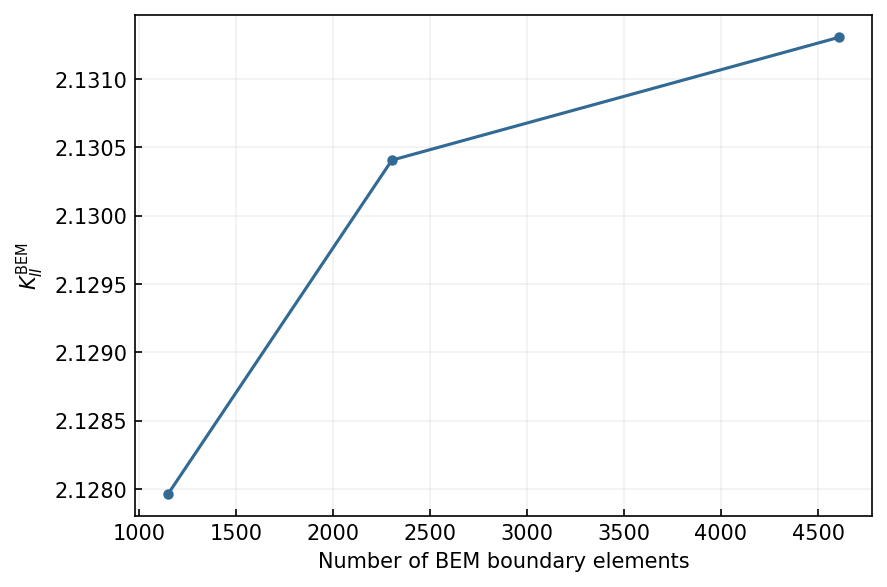

In [2]:
# Independent direct, constant-element BEM: H u = G t.
# Physical-boundary elements only; no KM-network coefficients or fictitious sources.
def _bem_integral_block(x,c,t,n,L,mu,kappa):
    d=c[None,:,:]-x[:,None,:]
    alpha=np.einsum('ijk,jk->ij',d,t); beta=np.einsum('ijk,jk->ij',d,n)
    s0=alpha-L[None,:]/2;s1=alpha+L[None,:]/2
    cop=np.abs(beta)<1e-13*max(1,float(np.max(L)))
    ab=np.where(cop,1.,abs(beta)); bb=np.where(cop,0.,beta)
    r0=s0*s0+bb*bb;r1=s1*s1+bb*bb
    da=np.arctan2(ab*(s1-s0),ab*ab+s0*s1)
    I0=np.where(cop,0,da/ab); I1=.5*np.log(r1/r0)
    F0=s0*.5*np.log(r0)-s0+np.where(cop,0,ab*np.arctan(s0/ab))
    F1=s1*.5*np.log(r1)-s1+np.where(cop,0,ab*np.arctan(s1/ab))
    logint=F1-F0
    nn=np.where(cop,0,ab*da);tt=L[None,:]-nn;tn=bb*I1
    Tt=np.einsum('ji,jk->jik',t,t)[None,:,:,:]
    Nn=np.einsum('ji,jk->jik',n,n)[None,:,:,:]
    Tn=np.einsum('ji,jk->jik',t,n)[None,:,:,:]
    Nt=np.einsum('ji,jk->jik',n,t)[None,:,:,:]
    eye=np.eye(2)[None,None,:,:]; C=1/(2*np.pi*mu*(kappa+1))
    G=C*(-kappa*logint[:,:,None,None]*eye+tt[:,:,None,None]*Tt+nn[:,:,None,None]*Nn+tn[:,:,None,None]*(Tn+Nt))
    ds=s1/r1-s0/r0
    jtt=.5*(I0-ds);jnn=.5*(I0+ds);jtn=-.5*bb*(1/r1-1/r0)
    H=C*mu*((kappa-1)*(I1[:,:,None,None]*(Tn-Nt)-(bb*I0)[:,:,None,None]*eye)-4*bb[:,:,None,None]*(jtt[:,:,None,None]*Tt+jnn[:,:,None,None]*Nn+jtn[:,:,None,None]*(Tn+Nt)))
    nr,nc=len(x),len(c)
    return (H.transpose(0,2,1,3).reshape(2*nr,2*nc),
            G.transpose(0,2,1,3).reshape(2*nr,2*nc))

def bem_panel_matrices(c,t,n,L,mu,kappa):
    count=len(c)
    H=np.empty((2*count,2*count));G=np.empty_like(H)
    for first in range(0,count,96):
        last=min(first+96,count)
        H[2*first:2*last],G[2*first:2*last]=_bem_integral_block(c[first:last],c,t,n,L,mu,kappa)
    H.flat[::2*count+1]+=.5
    return H,G

def solve_bem_mode_ii(a=1,b=2,h=6,E=1,nu=.3,tau=1,nbase=64,grade=2,plane_strain=True):
    mu=E/(2*(1+nu)); kappa=3-4*nu if plane_strain else (3-nu)/(1+nu)
    p=[]; tags=[]
    def segment(nodes,tag):
        p.extend(zip(nodes[:-1],nodes[1:]));tags.extend([tag]*(len(nodes)-1))
    u=np.linspace(0,1,2*nbase+1)
    segment(np.column_stack((a*(1-(1-u)**grade),0*u)),'crack')
    segment(np.column_stack((a+(b-a)*u**grade,0*u)),'ligament')
    u=np.linspace(0,1,2*nbase+1);segment(np.column_stack((b+0*u,h*u)),'right')
    u=np.linspace(0,1,nbase+1);segment(np.column_stack((b*(1-u),h+0*u)),'top')
    u=np.linspace(0,1,2*nbase+1);segment(np.column_stack((0*u,h*(1-u))),'left')
    p=np.asarray(p);tags=np.asarray(tags);c=p.mean(1);v=p[:,1]-p[:,0];L=np.linalg.norm(v,axis=1);t=v/L[:,None];norm=np.column_stack((t[:,1],-t[:,0]));N=len(c)
    H,G=bem_panel_matrices(c,t,norm,L,mu,kappa)
    uk=np.full((N,2),np.nan);tk=uk.copy()
    tk[tags=='crack']=0; tk[tags=='top']=(tau,0);tk[tags=='right']=(0,tau)
    uk[tags=='left',1]=0;tk[tags=='left',0]=0
    uk[tags=='ligament',0]=0;tk[tags=='ligament',1]=0
    iu=np.isnan(uk).ravel();u0=np.nan_to_num(uk).ravel();t0=np.nan_to_num(tk).ravel()
    M=np.where(iu[None,:],H,-G); rhs=G@t0-H@u0
    rigid_error=float(np.max(abs(H@np.tile([1,0],N))))
    del H,G
    gauge=np.zeros(2*N);ig=2*np.flatnonzero(tags=='left')[len(np.flatnonzero(tags=='left'))//2];gauge[ig]=1
    M=np.vstack((M,gauge));rhs=np.r_[rhs,0]
    scale=np.linalg.norm(M,axis=0);scaled=np.array(M,order='F',copy=True);scaled/=scale
    x=scipy_lstsq(scaled,rhs,cond=1e-12,lapack_driver='gelsy',overwrite_a=True)[0]/scale
    del scaled
    uv=np.where(iu,x,u0).reshape(N,2);tv=np.where(iu,t0,x).reshape(N,2)
    fits=[];fit_counts=[];fit_residuals=[]
    for low,high in [(0.002,.02),(.005,.05),(.01,.08)]:
        mask=(tags=='crack')&((a-c[:,0])/a>=low)&((a-c[:,0])/a<=high)
        if mask.sum()<8: raise ValueError('BEM crack-tip fitting needs at least 8 elements per window')
        r=(a-c[mask,0])/a;mat=np.column_stack((0*r+1,np.sqrt(r),r,r**1.5,r*r))
        cf=np.linalg.lstsq(mat,uv[mask,0],rcond=None)[0]
        fit_counts.append(int(mask.sum()))
        fit_residuals.append(float(np.linalg.norm(mat@cf-uv[mask,0])/max(np.linalg.norm(uv[mask,0]),1e-30)))
        fits.append(2*mu/(kappa+1)*np.sqrt(2*np.pi/a)*cf[1])
    bie_residual=float(np.linalg.norm(M@x-rhs)/max(np.linalg.norm(rhs),1e-30))
    resultant=np.sum(tv*L[:,None],axis=0)
    moment=float(np.sum((c[:,0]*tv[:,1]-c[:,1]*tv[:,0])*L))
    return dict(c=c,tags=tags,u=uv,t=tv,L=L,n=norm,K=np.asarray(fits),
                fit_counts=fit_counts,fit_residuals=fit_residuals,
                KII=float(fits[-1]),bie_residual=bie_residual,rigid_error=rigid_error,
                resultant=resultant,moment=moment,nbase=nbase,n_elements=N)

def compute_bem_reference():
    # All geometry/material/loading and discretization settings form the cache key.
    key=(a,b,h,E,nu,tau0,bool(cfg["plane_strain"]),tuple(cfg["bem_mesh_levels"]),
         cfg["bem_grade"],cfg["bem_mesh_tolerance"],cfg["bem_fit_tolerance"])
    cache=globals().setdefault("_BEM_REFERENCE_CACHE",{})
    if key in cache:
        print("Reusing BEM reference for unchanged geometry/material/loading.")
        return cache[key]
    records=[];previous=None;accepted=False
    try:
        from threadpoolctl import threadpool_limits
        context=threadpool_limits(limits=cfg["bem_blas_threads"])
    except ImportError:
        from contextlib import nullcontext
        context=nullcontext()
    with context:
        for level in cfg["bem_mesh_levels"]:
            start=time.perf_counter()
            out=solve_bem_mode_ii(a,b,h,E,nu,tau0,int(level),cfg["bem_grade"],cfg["plane_strain"])
            kii=out["KII"]
            change=np.nan if previous is None else abs(kii-previous)/max(abs(kii),1e-30)
            fit_spread=float(np.ptp(out["K"])/max(abs(kii),1e-30))
            record=dict(nbase=int(level),elements=out["n_elements"],KII=kii,
                        mesh_change=change,fit_spread=fit_spread,bie_residual=out["bie_residual"],
                        elapsed=time.perf_counter()-start)
            records.append(record)
            print(f"BEM Ne={record['elements']:5d}: KII={kii:.9f}, "
                  f"mesh change={100*change:.4f}%, fit spread={100*fit_spread:.4f}%, "
                  f"BIE residual={out['bie_residual']:.2e}, time={record['elapsed']:.2f}s",flush=True)
            accepted=(previous is not None and change<=cfg["bem_mesh_tolerance"]
                      and fit_spread<=cfg["bem_fit_tolerance"] and out["rigid_error"]<1e-9
                      and out["bie_residual"]<1e-3 and abs(kii)>1e-12)
            previous=kii
            if accepted:break
    if not accepted:
        raise RuntimeError("BEM reference did not pass mesh/fit checks. Increase bem_mesh_levels; "
                           "do not interpret KM-vs-BEM differences as accurate errors yet.")
    result=dict(solution=out,history=records,KII=out["KII"],mesh_change=change,fit_spread=fit_spread)
    cache[key]=result
    return result

bem_reference=compute_bem_reference()
KII_REF=bem_reference["KII"]
print(f"Finite-geometry BEM reference: a={a:g}, b={b:g}, h={h:g}, KII={KII_REF:.10f}")
print("Reference checks: mesh change and extraction-window spread are numerical diagnostics, not rigorous error bounds.")
fig,ax=plt.subplots(figsize=(5.8,3.8),dpi=150,constrained_layout=True)
ax.plot([r["elements"] for r in bem_reference["history"]],
        [r["KII"] for r in bem_reference["history"]],"o-",color="#326A93",lw=1.5,ms=4)
ax.set_xlabel("Number of BEM boundary elements");ax.set_ylabel(r"$K_{II}^{\mathrm{BEM}}$")
ax.tick_params(direction="in");ax.grid(alpha=.18)
maybe_savefig(fig,"bem_reference_convergence.png");plt.show()
if cfg["save_outputs"]:
    import csv
    folder=Path(cfg["output_dir"]);folder.mkdir(parents=True,exist_ok=True)
    with (folder/"bem_reference_convergence.csv").open("w",newline="",encoding="utf-8-sig") as stream:
        writer=csv.DictWriter(stream,fieldnames=list(bem_reference["history"][0]))
        writer.writeheader();writer.writerows(bem_reference["history"])
    sol=bem_reference["solution"]
    np.savez(folder/"bem_reference.npz",centers=sol["c"],displacement=sol["u"],traction=sol["t"],
             tags=sol["tags"],KII=KII_REF,a=a,b=b,h=h,E=E,nu=nu,tau0=tau0,
             plane_strain=cfg["plane_strain"])


## 几何与源点
只保留人工矩形边界上的外部源点。上边与右边均施加 $\sigma_{xy}=\tau_0$；左边采用 $u_y=0,\sigma_{xx}=0$；韧带采用 $u_x=0,\sigma_{yy}=0$，裂面无牵引。

Exterior sources: 252; local crack-tip sources: 0


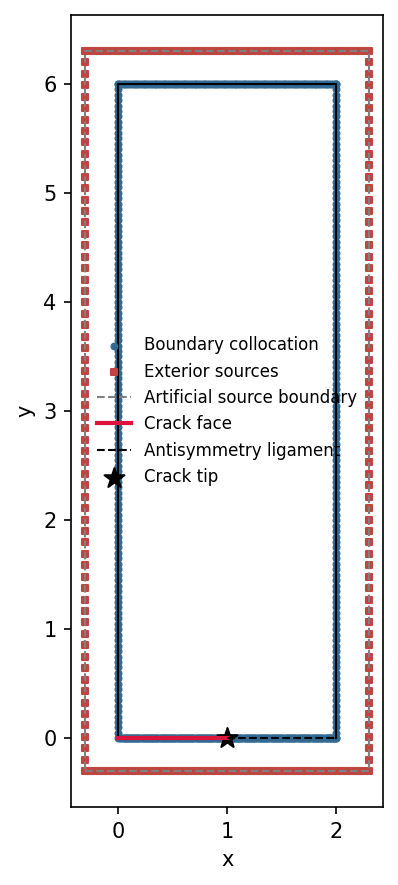

In [3]:
def generate_boundary_points(counts=None, midpoint=False):
    counts = cfg if counts is None else counts
    def line(lo, hi, n):
        if midpoint:
            return lo + (np.arange(n)+0.5)*(hi-lo)/n
        return np.linspace(lo, hi, n)
    return {
        "top": line(0, b, counts["n_top"]) + 1j*h,
        "right": b + 1j*line(0, h, counts["n_side"]),
        "left": 1j*line(0, h, counts["n_side"]),
        "crack": line(0.02*a, 0.98*a, counts["n_crack"]) + 1j*cfg["eps_crack"],
        "ligament": line(1.02*a, b, counts["n_ligament"]) + 0j,
    }

def generate_source_points(n=None, scale=1.0):
    """Scale both baseline exterior distances; q=1 reproduces the original."""
    n = cfg["n_src_side"] if n is None else int(n)
    scale = float(scale)
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("Source expansion scale must be finite and positive")
    mx = scale * cfg["src_margin_x_factor"] * b
    my = scale * cfg["src_margin_y_factor"] * h
    if n < 2 or min(mx, my) <= 0:
        raise ValueError("Require n>=2 and positive exterior source margins")
    xs, ys = np.linspace(-mx, b+mx, n), np.linspace(-my, h+my, n)
    sources = np.r_[xs-1j*my, xs+1j*(h+my),
                    -mx+1j*ys[1:-1], b+mx+1j*ys[1:-1]]
    assert np.all((sources.real < 0) | (sources.real > b) |
                  (sources.imag < 0) | (sources.imag > h))
    return sources

bnd_pts = generate_boundary_points()
src_pts = generate_source_points()
print(f"Exterior sources: {len(src_pts)}; local crack-tip sources: 0")
fig, ax = plt.subplots(figsize=(5.5, 6), dpi=150)
for i, (name, z) in enumerate(bnd_pts.items()):
    ax.scatter(z.real, z.imag, s=8, color="#326A93",
               label="Boundary collocation" if i == 0 else None)
ax.scatter(src_pts.real, src_pts.imag, s=9, marker="s", color="#BE4540", label="Exterior sources")
mx, my = cfg["src_margin_x_factor"]*b, cfg["src_margin_y_factor"]*h
ax.plot([-mx,b+mx,b+mx,-mx,-mx],[-my,-my,h+my,h+my,-my],"--",color="gray",lw=1,label="Artificial source boundary")
ax.plot([0,0,b,b],[0,h,h,0],"k-",lw=1)
ax.plot([0,a],[0,0],color="crimson",lw=2,label="Crack face")
ax.plot([a,b],[0,0],"k--",lw=1,label="Antisymmetry ligament")
ax.scatter([a],[0],s=100,marker="*",color="black",label="Crack tip")
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(fontsize=8,frameon=False); fig.tight_layout()
maybe_savefig(fig, "sources.png"); plt.show()

## KM 复势与二型 Williams 富集
令 $z=x+iy,w=z-a,p=n/2$。采用
\[
\phi_p=-\frac{i}{\sqrt{2\pi}}h^{1/2-p}w^p,\qquad
\psi_p=-(p+1)\phi_p-a\phi'_p.
\]
其中平移修正 $-a\phi'_p$ 不可省略；$p=1/2$ 的系数为 $K_{II}$，高阶系数独立学习。

在当前 $u_x+iu_y$、正 $K_{II}$ 对应裂尖前方正 $\sigma_{xy}$ 的约定下，正确位移为
\[
u_y=-\frac{K_{II}}{2\mu}\sqrt{\frac r{2\pi}}\cos\frac\theta2(\kappa-2+\cos\theta).
\]
这表示整个角函数前的负号，不表示所有位置的 $u_y$ 数值必然为负。符号由本构一致性确定，不能只按与参考值的距离来选择。

In [4]:
QUANTITIES = ("ux", "uy", "sxx", "syy", "sxy")

def km_response(z, phi, dphi, ddphi, psi, dpsi):
    stress_sum = 4*dphi.real
    stress_diff = 2*(z.conjugate()*ddphi+dpsi)
    displacement = (kappa*phi-z*dphi.conjugate()-psi.conjugate())/(2*mu)
    return np.column_stack((displacement.real, displacement.imag,
                            (stress_sum-stress_diff.real)/2,
                            (stress_sum+stress_diff.real)/2,
                            stress_diff.imag/2))

def complex_point_force_potential_response(z, source, force):
    q = z-source
    den = 2*np.pi*(kappa+1)
    phi = -force/den*np.log(q) + force/(2*np.pi*kappa*(kappa+1))
    dphi, ddphi = -force/den/q, force/den/q**2
    psi = kappa*force.conjugate()/den*np.log(q) + force*source.conjugate()/den/q
    dpsi = kappa*force.conjugate()/den/q - force*source.conjugate()/den/q**2
    return km_response(z, phi, dphi, ddphi, psi, dpsi)

def mode_ii_williams_response(z, p=0.5):
    if p < 0.5 or abs((p-0.5)-round(p-0.5)) > 1e-12:
        raise ValueError("Use p=0.5, 1.5, 2.5, ...")
    z = np.asarray(z, dtype=np.complex128).reshape(-1)
    w = z-a
    if np.any(np.abs(w) == 0):
        raise ValueError("Do not evaluate exactly at the singular crack tip")
    C = -1j / np.sqrt(2*np.pi) * h**(0.5-p)
    phi, dphi = C*w**p, C*p*w**(p-1)
    ddphi = C*p*(p-1)*w**(p-2)
    psi = -(p+1)*phi-a*dphi
    dpsi = -(p+1)*dphi-a*ddphi
    return km_response(z, phi, dphi, ddphi, psi, dpsi)

def build_basis_columns(points, sources=None, uy_sign=-1):
    # uy_sign=+1 deliberately reproduces the OLD, inconsistent leading uy.
    # This flag is diagnostic only. All physical predictions use uy_sign=-1.
    if uy_sign not in (-1, 1):
        raise ValueError("uy_sign must be -1 or +1")
    z = np.asarray(points, dtype=np.complex128).reshape(-1)
    sources = src_pts if sources is None else sources
    cols = [complex_point_force_potential_response(z,s,P)
            for s in sources for P in (1+0j, 1j)]
    cols += [mode_ii_williams_response(z,p) for p in cfg["higher_williams_orders"]]
    leading = mode_ii_williams_response(z,0.5)
    if uy_sign == 1:
        leading[:,1] *= -1
    cols.append(leading)
    array = np.stack(cols,axis=2)
    assert np.isfinite(array).all()
    return {q: array[:,i,:] for i,q in enumerate(QUANTITIES)}

BOUNDARY_BLOCKS = [
    ("top","syy",0.0,"w_top"), ("top","sxy",tau0,"w_top"),
    ("right","sxx",0.0,"w_right"), ("right","sxy",tau0,"w_right"),
    ("left","uy",0.0,"w_left"), ("left","sxx",0.0,"w_left"),
    ("crack","syy",0.0,"w_crack"), ("crack","sxy",0.0,"w_crack"),
    ("ligament","ux",0.0,"w_ligament"), ("ligament","syy",0.0,"w_ligament"),
]

def assemble_system(points=bnd_pts, sources=None, uy_sign=-1):
    matrices = {g:build_basis_columns(z,sources,uy_sign) for g,z in points.items()}
    rows, rhs = [], []
    for g,q,target,key in BOUNDARY_BLOCKS:
        block = matrices[g][q]
        factor = np.sqrt(cfg[key]/len(block))
        rows.append(factor*block)
        rhs.append(np.full((len(block),1),factor*target))
    A, rhs = np.vstack(rows), np.vstack(rhs)
    scale = np.linalg.norm(A,axis=0)
    scale = np.where(scale>0,scale,1.0)
    return matrices, A/scale, rhs, scale

basis, A, rhs, col_scale = assemble_system()
n_unknowns = A.shape[1]

print(f"Equations / coefficient unknowns: {A.shape}; source parameters: 2")

_bem_expected={("top","syy"):0.,("top","sxy"):tau0,("right","sxx"):0.,("right","sxy"):tau0,
               ("left","uy"):0.,("left","sxx"):0.,("crack","syy"):0.,("crack","sxy"):0.,
               ("ligament","ux"):0.,("ligament","syy"):0.}
_actual={(g,q):target for g,q,target,key in BOUNDARY_BLOCKS}
if _actual!=_bem_expected:
    raise ValueError("KM and BEM boundary conditions differ. Update the independent BEM before comparison.")


Equations / coefficient unknowns: (1126, 507); source parameters: 2


## 本构一致性核查
保留正确二型 Williams 复势的本构核查，不执行符号比较中的最小二乘求解。


In [5]:
def tip_constitutive_error(uy_sign):
    z = np.array([a+0.3+0.2j, a-0.2+0.3j, a+0.6+0.4j])
    def field(zz):
        out = mode_ii_williams_response(zz,0.5)
        if uy_sign == 1: out[:,1] *= -1
        return out
    delta = 1e-6*a
    dx = (field(z+delta)-field(z-delta))/(2*delta)
    dy = (field(z+1j*delta)-field(z-1j*delta))/(2*delta)
    exx, eyy, gamma = dx[:,0],dy[:,1],dy[:,0]+dx[:,1]
    derived = np.column_stack(((lam+2*mu)*exx+lam*eyy,
                               lam*exx+(lam+2*mu)*eyy,mu*gamma))
    exact = field(z)[:,2:]
    return np.linalg.norm(derived-exact)/np.linalg.norm(exact)

assert tip_constitutive_error(-1) < 1e-7
print("Mode-II Williams constitutive consistency verified")


Mode-II Williams constitutive consistency verified


## 多组初始位置的冷启动联合训练
source_raw 的有界 sigmoid 映射保证源点始终位于四分之一域外。每组初始位置固定一次列归一化尺度，后续仅重建随源点移动的基本解列；Williams 列保持不变。训练目标为原加权边界损失加正则项，KII 不受正则。最低总损失状态同时恢复源点参数和全部系数，不根据参考差异挑选结果。

记录编号包括初值及每次 Adam 步或 L-BFGS 外层调用；L-BFGS 每次调用最多含 lbfgs_max_iter 次内部迭代。零系数初值下源点梯度为零，系数更新后源点梯度随之产生。


In [6]:
import copy
import csv

def source_points_numpy(initial_pair, n=None):
    n = cfg["n_src_side"] if n is None else int(n)
    fx,fy = initial_pair
    mx,my = fx*b,fy*h
    xs,ys = np.linspace(-mx,b+mx,n),np.linspace(-my,h+my,n)
    return np.r_[xs-1j*my,xs+1j*(h+my),
                 -mx+1j*ys[1:-1],b+mx+1j*ys[1:-1]]


def differentiable_force_columns(points,sources):
    z=points[:,None]; s=sources[None,:]; q=z-s
    den=2*np.pi*(kappa+1)
    logq=torch.log(q)
    responses=[]
    for force in (1.+0j,1j):
        P=torch.tensor(force,dtype=torch.complex128,device=points.device)
        phi=-P/den*logq+P/(2*np.pi*kappa*(kappa+1))
        dphi=-P/(den*q); ddphi=P/(den*q**2)
        psi=kappa*P.conj()/den*logq+P*s.conj()/(den*q)
        dpsi=kappa*P.conj()/(den*q)-P*s.conj()/(den*q**2)
        ss=4*dphi.real; sd=2*(z.conj()*ddphi+dpsi)
        u=(kappa*phi-z*dphi.conj()-psi.conj())/(2*mu)
        responses.append((u.real,u.imag,(ss-sd.real)/2,
                          (ss+sd.real)/2,sd.imag/2))
    return {q:torch.stack((responses[0][j],responses[1][j]),dim=2).reshape(len(points),-1)
            for j,q in enumerate(QUANTITIES)}


class AdaptiveModeIINetwork(torch.nn.Module):
    def __init__(self,initial_pair):
        super().__init__()
        lo=torch.tensor([cfg["source_margin_x_bounds"][0],cfg["source_margin_y_bounds"][0]],device=device)
        hi=torch.tensor([cfg["source_margin_x_bounds"][1],cfg["source_margin_y_bounds"][1]],device=device)
        initial=torch.tensor(initial_pair,device=device)
        if not torch.all((initial>lo)&(initial<hi)):
            raise ValueError("Initial source factors must lie strictly inside bounds")
        self.register_buffer("factor_lo",lo); self.register_buffer("factor_hi",hi)
        self.source_raw=torch.nn.Parameter(torch.logit((initial-lo)/(hi-lo)))
        self.register_buffer("edge_t",torch.linspace(0.,1.,cfg["n_src_side"],device=device))
        self.groups=list(bnd_pts)
        self.lengths=[len(bnd_pts[g]) for g in self.groups]
        self.register_buffer("z_boundary",torch.as_tensor(np.concatenate([bnd_pts[g] for g in self.groups]),
                                                         dtype=torch.complex128,device=device))
        sources=source_points_numpy(initial_pair)
        _,initial_A,initial_rhs,scale=assemble_system(sources=sources)
        self.register_buffer("col_scale",torch.as_tensor(scale[:,None],device=device))
        self.register_buffer("target",torch.as_tensor(initial_rhs,device=device))
        self.theta=torch.nn.Parameter(torch.zeros((initial_A.shape[1],1),device=device))
        nforce=2*len(sources)
        # Only source-independent enrichment columns are retained.
        for j,g in enumerate(self.groups):
            fixed=build_basis_columns(bnd_pts[g],sources=sources)
            for q in QUANTITIES:
                self.register_buffer(f"fixed_{j}_{q}",torch.as_tensor(fixed[q][:,nforce:],device=device))

    def source_factors(self):
        return self.factor_lo+(self.factor_hi-self.factor_lo)*torch.sigmoid(self.source_raw)

    def sources(self):
        fx,fy=self.source_factors(); mx,my=fx*b,fy*h
        xs=-mx+(b+2*mx)*self.edge_t
        ys=-my+(h+2*my)*self.edge_t
        # Ordering is identical to build_basis_columns and source_points_numpy.
        return torch.cat((torch.complex(xs,-my.expand_as(xs)),
                          torch.complex(xs,(h+my).expand_as(xs)),
                          torch.complex(-mx.expand_as(ys[1:-1]),ys[1:-1]),
                          torch.complex((b+mx).expand_as(ys[1:-1]),ys[1:-1])))

    def coeffs(self):
        return self.theta/self.col_scale

    def boundary_matrix(self):
        force=differentiable_force_columns(self.z_boundary,self.sources())
        split={q:torch.split(values,self.lengths) for q,values in force.items()}
        group_index={g:j for j,g in enumerate(self.groups)}
        rows=[]
        for g,q,target,key in BOUNDARY_BLOCKS:
            j=group_index[g]
            physical=torch.cat((split[q][j],getattr(self,f"fixed_{j}_{q}")),dim=1)
            rows.append(np.sqrt(cfg[key]/self.lengths[j])*physical/self.col_scale.T)
        return torch.cat(rows,dim=0)

    def losses(self):
        boundary=torch.sum((self.boundary_matrix()@self.theta-self.target)**2)
        regularization=cfg["lambda_reg"]*torch.mean(self.theta[:-1]**2)
        return boundary,regularization,boundary+regularization


def train_adaptive_case(initial_pair):
    net=AdaptiveModeIINetwork(initial_pair)
    assert torch.count_nonzero(net.theta).item()==0  # cold start incl. KII
    history=[];best_loss=float("inf");best_state=None;best_record=0
    start=time.perf_counter()
    def record(stage,iteration):
        nonlocal best_loss,best_state,best_record
        with torch.no_grad():
            boundary,reg,total=net.losses()
            fx,fy=net.source_factors().tolist(); kii=net.coeffs()[-1,0].item()
        row=dict(record=len(history),stage=stage,iteration=iteration,
                 alpha_x=fx,alpha_y=fy,KII=kii,
                 relative_difference_percent=100*abs(kii-KII_REF)/abs(KII_REF),
                 boundary_loss=boundary.item(),boundary_residual=math.sqrt(max(boundary.item(),0)),
                 regularization=reg.item(),total_loss=total.item())
        history.append(row)
        if row["total_loss"]<best_loss:
            best_loss=row["total_loss"];best_state=copy.deepcopy(net.state_dict());best_record=row["record"]
        return row
    def report(row):
        print(f"  {row['stage']} {row['iteration']:4d}: "
              f"alpha=({row['alpha_x']:.6f},{row['alpha_y']:.6f}), "
              f"KII={row['KII']:.9f}, residual={row['boundary_residual']:.3e}, "
              f"difference={row['relative_difference_percent']:.3f}%, "
              f"loss={row['total_loss']:.3e}",flush=True)
    print(f"\nCold start alpha={tuple(initial_pair)}; all coefficients and KII = 0",flush=True)
    report(record("initial",0))
    if cfg["adam_steps"]>0:
        opt=torch.optim.Adam(net.parameters(),lr=cfg["adam_lr"])
        for iteration in range(1,cfg["adam_steps"]+1):
            opt.zero_grad();net.losses()[-1].backward();opt.step()
            row=record("Adam",iteration)
            if iteration==1 or iteration%cfg["print_every"]==0:report(row)
    net.load_state_dict(best_state)
    if cfg["lbfgs_epochs"]>0:
        opt=torch.optim.LBFGS(net.parameters(),lr=1.,max_iter=cfg["lbfgs_max_iter"],
                             max_eval=cfg["lbfgs_max_iter"]+10,history_size=100,
                             tolerance_grad=1e-12,tolerance_change=1e-14,
                             line_search_fn="strong_wolfe")
        for iteration in range(1,cfg["lbfgs_epochs"]+1):
            def closure():
                opt.zero_grad();loss=net.losses()[-1];loss.backward();return loss
            opt.step(closure);row=record("L-BFGS",iteration)
            if iteration==1 or iteration%cfg["print_every"]==0:report(row)
    net.load_state_dict(best_state)
    with torch.no_grad():
        final_sources=net.sources().cpu().numpy().copy()
        final_coeff=net.coeffs().cpu().numpy().copy()
        fx,fy=net.source_factors().tolist()
    result=dict(initial_pair=tuple(initial_pair),final_pair=(fx,fy),model=net,
                sources=final_sources,coefficients=final_coeff,
                history=history,best_record=best_record,elapsed=time.perf_counter()-start)
    print(f"  Restored joint best state at record {best_record}; time={result['elapsed']:.2f}s",flush=True)
    return result


PLOT_CFG = dict(
    figsize=(15, 8.6), label_fontsize=15, tick_fontsize=12,
    legend_fontsize=13, line_width=1.8,
    save_dpi=400, show_grid=False, show_best_markers=False,
    save_outputs=True, show=True,
)

def normalize_live_results(results, reference):
    return [dict(summary=dict(initial_margin_x=float(r['initial_pair'][0]),
                              initial_margin_y=float(r['initial_pair'][1]),
                              KII_reference=float(reference), best_record=int(r['best_record'])),
                 history=r['history']) for r in results]

def plot_mode_ii_histories(results, base_cfg, plot_cfg=None):
    settings = dict(PLOT_CFG)
    if plot_cfg is not None:
        settings.update(plot_cfg)
    if not results:
        raise ValueError('No source-study results are available.')
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
    panels = [
        ('alpha_x', r'$\alpha_x=m_x/b$', False),
        ('alpha_y', r'$\alpha_y=m_y/h$', False),
        ('KII', r'Stress intensity factor $K_{II}$', False),
        ('boundary_residual', r'Boundary residual $\sqrt{L_{\mathrm{boundary}}}$', True),
        ('relative_difference_percent', r'Difference from BEM in $K_{II}$ (%)', True),
        ('total_loss', 'Total training loss', True),
    ]
    style = {
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'DejaVu Serif'],
        'mathtext.fontset': 'stix',
        'font.size': 12,
        'axes.linewidth': .85,
        'pdf.fonttype': 42,
        'svg.fonttype': 'none',
    }
    with plt.rc_context(style):
        fig, axes = plt.subplots(2, 3, figsize=settings['figsize'],
                                 dpi=150, constrained_layout=True)
        fig.set_constrained_layout_pads(w_pad=.07, h_pad=.07, wspace=.06, hspace=.06)
        for ax, (key, ylabel, logscale) in zip(axes.ravel(), panels):
            all_values, all_iterations = [], []
            for index, result in enumerate(results):
                history, summary = result['history'], result['summary']
                x = np.asarray([float(row['record']) for row in history])
                values = np.asarray([float(row[key]) for row in history])
                if not np.isfinite(x).all() or not np.isfinite(values).all():
                    raise ValueError(f'Non-finite history values in {key}.')
                all_values.extend(values)
                all_iterations.extend(x)
                # A zero cannot be represented on a logarithmic axis.
                plotted = np.where(values > 0., values, np.nan) if logscale else values
                label = rf"$({float(summary['initial_margin_x']):g},\,{float(summary['initial_margin_y']):g})$"
                color = colors[index % len(colors)]
                ax.plot(x, plotted, color=color, lw=settings['line_width'], label=label)
                if settings['show_best_markers']:
                    best_index = next((j for j, row in enumerate(history)
                                       if int(float(row['record'])) == int(summary['best_record'])), None)
                    if best_index is not None and np.isfinite(plotted[best_index]):
                        ax.plot(x[best_index], plotted[best_index], 'o', color=color,
                                ms=4.5, mfc='white', mew=1.1)
            if logscale:
                ax.set_yscale('log')
            if key == 'KII':
                refs = np.asarray([float(r['summary']['KII_reference']) for r in results])
                if not np.allclose(refs, refs[0], rtol=1e-10, atol=1e-12):
                    raise ValueError('The runs use different KII reference values.')
                ax.axhline(refs[0], color='#444444', ls='--', lw=1.2,
                           label='_nolegend_', zorder=1)
                ax.annotate(r'$K_{II}^{\mathrm{BEM}}$',
                            xy=(.98, refs[0]), xycoords=('axes fraction', 'data'),
                            xytext=(-3, -12), textcoords='offset points',
                            ha='right', va='top', color='#444444',
                            fontsize=settings['legend_fontsize'])
            if key in ('alpha_x', 'alpha_y'):
                low, high = min(all_values), max(all_values)
                span = max(high-low, .02)
                # Only the first source-parameter panel needs legend space.
                headroom = .35 if key == 'alpha_x' else .06
                ax.set_ylim(low-.06*span, high+headroom*span)
            ax.set_xlim(min(all_iterations), max(all_iterations))
            ax.set_xlabel('Iteration', fontsize=settings['label_fontsize'])
            ax.set_ylabel(ylabel, fontsize=settings['label_fontsize'])
            ax.tick_params(direction='in', top=True, right=True,
                           labelsize=settings['tick_fontsize'], length=4, width=.8)
            if settings['show_grid']:
                ax.grid(which='major', color='#dddddd', lw=.5, alpha=.55)
            else:
                ax.grid(False)
            if key != 'alpha_y':
                legend = ax.legend(
                    loc='lower right' if key == 'KII' else 'upper right',
                    ncol=2 if key == 'alpha_x' else 1, frameon=False,
                    fontsize=settings['legend_fontsize'],
                    handlelength=1.8, handletextpad=.45,
                    columnspacing=.85, labelspacing=.35, borderaxespad=.55)
                for line in legend.get_lines():
                    line.set_linewidth(settings['line_width'])
        if settings['save_outputs']:
            folder = Path(base_cfg['output_dir']).expanduser()
            folder.mkdir(parents=True, exist_ok=True)
            for extension in ('png', 'pdf'):
                path = folder / f'mode_ii_adaptive_convergence_case41_style.{extension}'
                fig.savefig(path, dpi=settings['save_dpi'], bbox_inches='tight', facecolor='white')
                print('Saved:', path.resolve())
        if settings['show']:
            plt.show()
        plt.close(fig)
    print('Iteration follows the recorded updates: one Adam step or one L-BFGS outer call; closure evaluations are not counted separately.')
    return fig, axes

def plot_adaptive_histories(results):
    normalized = normalize_live_results(results, KII_REF)
    fig, axes = plot_mode_ii_histories(normalized, cfg,
                                      {'save_outputs': cfg.get('save_outputs', False)})
    return fig


if cfg["ls_warm_start"]:
    raise ValueError("This notebook implements cold starts. Set ls_warm_start=False.")
if cfg["adam_steps"]<=0 and cfg["lbfgs_epochs"]<=0:
    raise ValueError("Enable at least one optimizer")
initial_pairs=[tuple(map(float,p)) for p in cfg["source_initial_pairs"]]
if not initial_pairs or len(set(initial_pairs))!=len(initial_pairs):
    raise ValueError("Provide distinct source initial pairs")
selected=tuple(cfg["selected_initial_pair"])
if selected not in initial_pairs:
    raise ValueError("selected_initial_pair must appear in source_initial_pairs")
adaptive_results=[train_adaptive_case(pair) for pair in initial_pairs]
adaptive_figure=plot_adaptive_histories(adaptive_results)

summary=[]
for result in adaptive_results:
    final=result["history"][result["best_record"]]
    summary.append(dict(alpha_x_initial=result["initial_pair"][0],alpha_y_initial=result["initial_pair"][1],
                        alpha_x_final=result["final_pair"][0],alpha_y_final=result["final_pair"][1],
                        KII=final["KII"],relative_difference_percent=final["relative_difference_percent"],
                        boundary_loss=final["boundary_loss"],total_loss=final["total_loss"],
                        best_record=result["best_record"],elapsed=result["elapsed"]))
    if cfg["save_outputs"]:
        folder=Path(cfg["output_dir"]);folder.mkdir(parents=True,exist_ok=True)
        fx,fy=result["initial_pair"];stem=f"initial_x_{fx:g}_y_{fy:g}"
        with (folder/f"{stem}_history.csv").open("w",newline="",encoding="utf-8-sig") as f:
            writer=csv.DictWriter(f,fieldnames=list(result["history"][0]));writer.writeheader();writer.writerows(result["history"])
        np.savez(folder/f"{stem}_best.npz",sources=result["sources"],coefficients=result["coefficients"],
                 initial_pair=result["initial_pair"],final_pair=result["final_pair"],best_record=result["best_record"])
if cfg["save_outputs"]:
    with (Path(cfg["output_dir"])/"adaptive_initial_final_summary.csv").open("w",newline="",encoding="utf-8-sig") as f:
        writer=csv.DictWriter(f,fieldnames=list(summary[0]));writer.writeheader();writer.writerows(summary)
print("\nInitial -> restored source parameters and KII:")
for row in summary:
    print(f"({row['alpha_x_initial']:.3f},{row['alpha_y_initial']:.3f}) -> "
          f"({row['alpha_x_final']:.6f},{row['alpha_y_final']:.6f}); "
          f"KII={row['KII']:.9f}, difference={row['relative_difference_percent']:.3f}%")

# Field plots and independent checks use a prespecified run, never the run with lowest reference error.
selected_result=next(r for r in adaptive_results if r["initial_pair"]==selected)
model=selected_result["model"]
src_pts=selected_result["sources"].copy()
coefficients=selected_result["coefficients"].copy()
col_scale=model.col_scale.detach().cpu().numpy().ravel()
theta_final=model.theta.detach().cpu().numpy().copy()
loss_history=[r["total_loss"] for r in selected_result["history"]]
KII_pred=float(coefficients[-1,0]);rel_err=abs(KII_pred-KII_REF)/abs(KII_REF)
best_origin=f"joint best record {selected_result['best_record']}"
print(f"Postprocessing initial pair={selected}; KII={KII_pred:.10f}, BEM difference={rel_err:.4%}")



Cold start alpha=(0.05, 0.02); all coefficients and KII = 0
  initial    0: alpha=(0.050000,0.020000), KII=0.000000000, residual=2.000e+00, difference=100.000%, loss=4.000e+00
  L-BFGS    1: alpha=(0.050390,0.020069), KII=0.629785513, residual=2.734e-01, difference=70.451%, loss=7.473e-02
  L-BFGS   10: alpha=(0.074583,0.026009), KII=2.162781732, residual=4.439e-03, difference=1.477%, loss=1.970e-05
  L-BFGS   20: alpha=(0.087440,0.026888), KII=2.165653691, residual=2.726e-03, difference=1.612%, loss=7.430e-06
  L-BFGS   30: alpha=(0.092485,0.026843), KII=2.164295575, residual=2.354e-03, difference=1.548%, loss=5.540e-06
  L-BFGS   40: alpha=(0.096199,0.026724), KII=2.163289078, residual=2.083e-03, difference=1.501%, loss=4.339e-06
  L-BFGS   50: alpha=(0.097972,0.026662), KII=2.163353963, residual=1.910e-03, difference=1.504%, loss=3.647e-06
  L-BFGS   60: alpha=(0.098608,0.026512), KII=2.162508098, residual=1.799e-03, difference=1.464%, loss=3.238e-06
  L-BFGS   70: alpha=(0.098530,


Initial -> restored source parameters and KII:
(0.050,0.020) -> (0.096161,0.024779); KII=2.157942403, difference=1.250%
(0.150,0.050) -> (0.516777,0.142064); KII=2.135225359, difference=0.184%
(0.300,0.100) -> (0.598808,0.245686); KII=2.135106743, difference=0.178%
(0.500,0.200) -> (0.598944,0.299945); KII=2.131665165, difference=0.017%
Postprocessing initial pair=(0.15, 0.05); KII=2.1352253589, BEM difference=0.1839%


## 独立配点与裂尖提取核查
在新的边界点检查残差。裂尖前方以 $\sqrt{2\pi r}\sigma_{xy}$ 检查 $K_{II}$；裂面切向位移采用含常数项的 $\sqrt r$ 拟合，避免微小平移残差经 $1/\sqrt r$ 放大。两种提取均不使用首阶系数作为拟合目标。

Independent boundary RMS (original, unweighted units):
  top       syy: 1.135e-04
  top       sxy: 1.322e-04
  right     sxx: 4.877e-04
  right     sxy: 5.655e-04
  left      uy : 1.201e-04
  left      sxx: 1.669e-04
  crack     syy: 1.342e-04
  crack     sxy: 1.532e-04
  ligament  ux : 2.118e-04
  ligament  syy: 2.970e-04
KII coefficient:             2.1352253589
KII ahead stress at r/a=1e-6:2.1352263346
KII upper-face sqrt(r) fit:  2.1352253598
Fitted face constant:        -1.011e-03


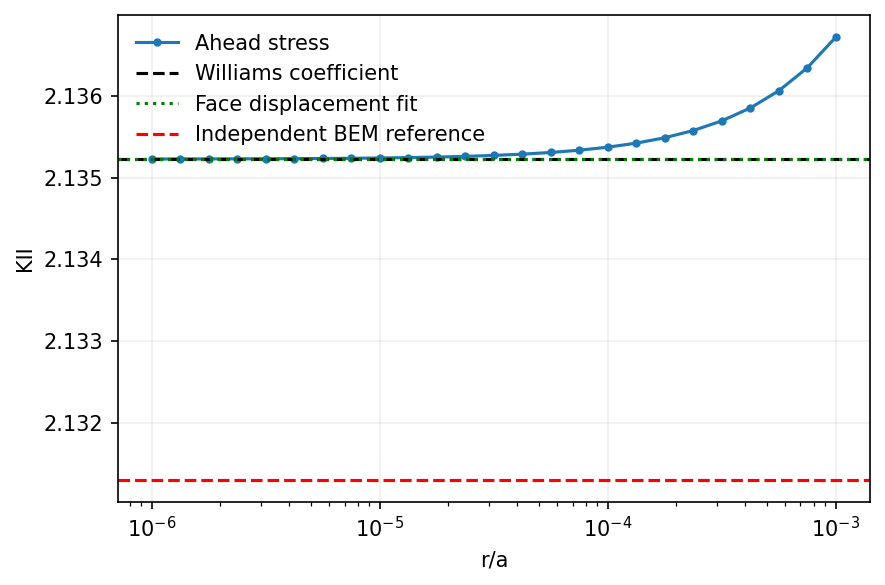

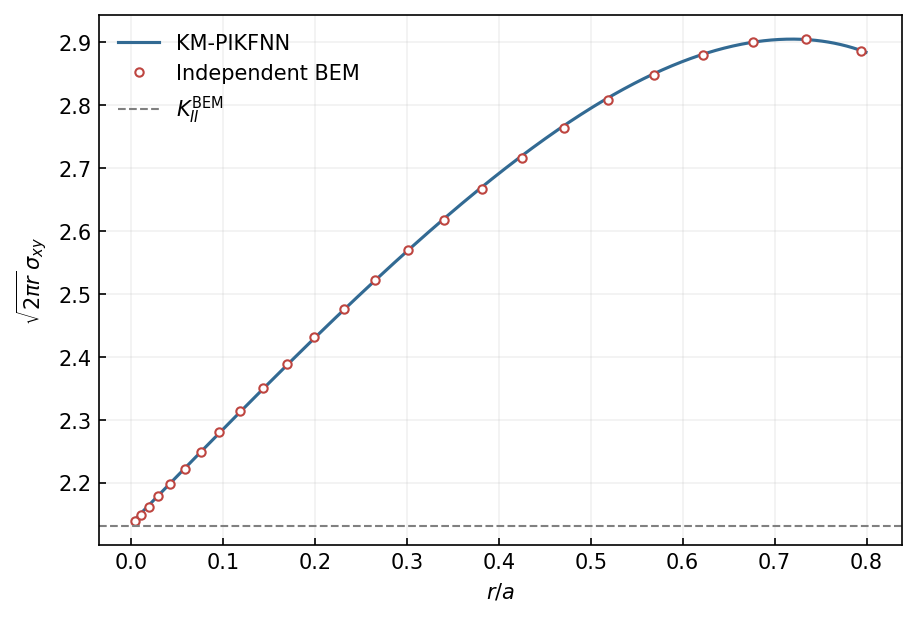

In [7]:
def evaluate_quantities(points, coeff=None, sources=None, batch_size=1500):
    points = np.asarray(points,dtype=np.complex128).reshape(-1)
    coeff = coefficients if coeff is None else np.asarray(coeff).reshape(-1,1)
    outs = {q:[] for q in QUANTITIES}
    for start in range(0,len(points),batch_size):
        bm = build_basis_columns(points[start:start+batch_size],sources)
        for q in QUANTITIES: outs[q].append((bm[q]@coeff).ravel())
    return {q:np.concatenate(parts) for q,parts in outs.items()}

validation_points = generate_boundary_points(
    {"n_top":177,"n_side":173,"n_crack":151,"n_ligament":149},midpoint=True)
validation_fields = {g:evaluate_quantities(z) for g,z in validation_points.items()}
print("Independent boundary RMS (original, unweighted units):")
for g,q,target,key in BOUNDARY_BLOCKS:
    rms = np.sqrt(np.mean((validation_fields[g][q]-target)**2))
    print(f"  {g:9s} {q:3s}: {rms:.3e}")

r_check = a*np.geomspace(1e-6,1e-3,25)
fa = evaluate_quantities(a+r_check+0j)
ff = evaluate_quantities(a-r_check+0j)
kii_stress = np.sqrt(2*np.pi*r_check)*fa["sxy"]
t = np.sqrt(r_check/a)
# ux = c0+c1*sqrt(r/a)+c2*(r/a)+...; c1 determines KII.
V = np.column_stack([t**j for j in range(5)])
fit = scipy_lstsq(V,ff["ux"],cond=1e-13,lapack_driver="gelsd")[0]
kii_displacement = 2*mu/(kappa+1)*np.sqrt(2*np.pi/a)*fit[1]
print(f"KII coefficient:             {KII_pred:.10f}")
print(f"KII ahead stress at r/a=1e-6:{kii_stress[0]:.10f}")
print(f"KII upper-face sqrt(r) fit:  {kii_displacement:.10f}")
print(f"Fitted face constant:        {fit[0]:.3e}")
fig,ax = plt.subplots(figsize=(6,4),dpi=150)
ax.semilogx(r_check/a,kii_stress,"o-",ms=3,label="Ahead stress")
ax.axhline(KII_pred,color="black",ls="--",label="Williams coefficient")
ax.axhline(kii_displacement,color="green",ls=":",label="Face displacement fit")
ax.axhline(KII_REF,color="red",ls="--",label="Independent BEM reference")
ax.set_xlabel("r/a");ax.set_ylabel("KII");ax.legend(frameon=False);ax.grid(alpha=.2)
fig.tight_layout();maybe_savefig(fig,"sif_checks.png");plt.show()

sol=bem_reference["solution"]
mask=sol["tags"]=="ligament"
rr=(sol["c"][mask,0]-a)/a
keep=(rr>=0.005)&(rr<=0.8)
xx=sol["c"][mask,0][keep]
# Bottom normal is (0,-1): sigma_xy=-t_x.
bem_sxy=-sol["t"][mask,0][keep]
km_sxy=evaluate_quantities(xx.astype(complex))["sxy"]
fig,ax=plt.subplots(figsize=(6,4),dpi=150,constrained_layout=True)
ax.plot(rr[keep],np.sqrt(2*np.pi*a*rr[keep])*km_sxy,color="#326A93",lw=1.5,label="KM-PIKFNN")
stride=max(1,len(xx)//24)
ax.plot(rr[keep][::stride],(np.sqrt(2*np.pi*a*rr[keep])*bem_sxy)[::stride],"o",ms=4,
        mfc="white",mec="#BE4540",label="Independent BEM")
ax.axhline(KII_REF,color="gray",ls="--",lw=1,label=r"$K_{II}^{\mathrm{BEM}}$")
ax.set_xlabel(r"$r/a$");ax.set_ylabel(r"$\sqrt{2\pi r}\,\sigma_{xy}$")
ax.legend(frameon=False);ax.grid(alpha=.18);ax.tick_params(direction="in")
maybe_savefig(fig,"km_vs_bem_ligament.png");plt.show()


## 场图
裂尖本身不参与求值，绘图时遮盖小范围奇异点。默认显示三幅应力场及两幅位移场。

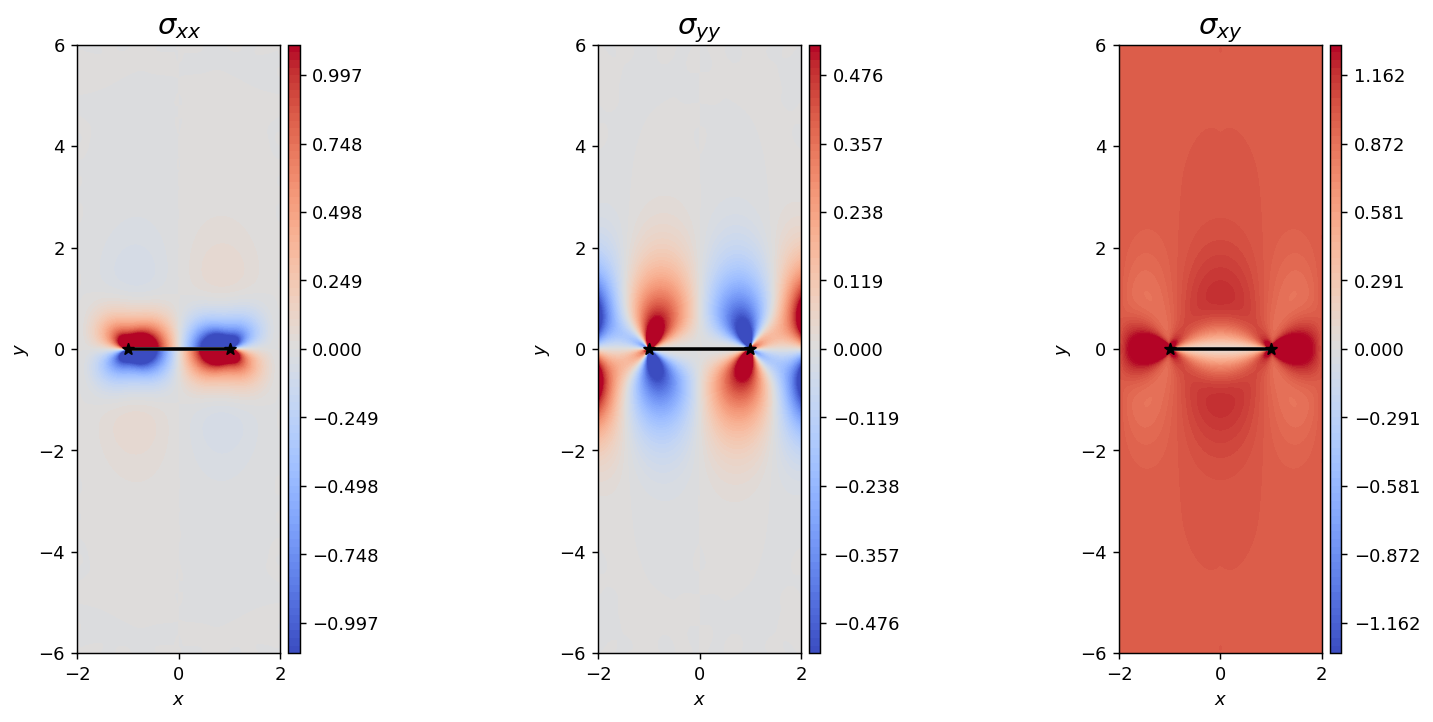

In [11]:
# =========================
# Full-plate stress contours
# =========================
x_quarter = np.linspace(0, b, cfg["nx_plot"])
y_quarter = np.linspace(0, h, cfg["ny_plot"])
Xq, Yq = np.meshgrid(x_quarter, y_quarter, indexing="xy")
z_quarter = (Xq + 1j * Yq).ravel()

# Hide the crack face and the singular tip neighborhood.
safe = (
    (np.abs(z_quarter - a) > 0.04 * a)
    & ~((np.abs(z_quarter.imag) < 0.005 * a)
        & (z_quarter.real < a))
)
quarter_values = evaluate_quantities(z_quarter[safe])

# Full-plate coordinates; avoid duplicating the symmetry axes.
x_full = np.r_[-x_quarter[:0:-1], x_quarter]
y_full = np.r_[-y_quarter[:0:-1], y_quarter]
X, Y = np.meshgrid(x_full, y_full, indexing="xy")

fields_full = {}
for q in ("sxx", "syy", "sxy"):
    data = np.full(z_quarter.size, np.nan)
    data[safe] = quarter_values[q]
    data = data.reshape(Xq.shape)

    # Mode II:
    # sxx and syy are odd across each symmetry axis.
    # sxy is even across both symmetry axes.
    sign = -1.0 if q in ("sxx", "syy") else 1.0

    upper_half = np.concatenate(
        (sign * data[:, :0:-1], data),
        axis=1,
    )
    fields_full[q] = np.concatenate(
        (sign * upper_half[:0:-1, :], upper_half),
        axis=0,
    )

fig, axes = plt.subplots(1, 3, figsize=(12, 6), dpi=130)
fig.subplots_adjust(
    left=.06, right=.93,
    bottom=.12, top=.90,
    wspace=.65,
)

for ax, q, label in zip(
    axes,
    ("sxx", "syy", "sxy"),
    (r"$\sigma_{xx}$", r"$\sigma_{yy}$", r"$\sigma_{xy}$"),
):
    data = fields_full[q]
    vmax = max(
        float(np.nanpercentile(np.abs(data), 98.5)),
        1e-12,
    )

    im = ax.contourf(
        X, Y, data,
        levels=np.linspace(-vmax, vmax, 81),
        cmap="coolwarm",
        extend="both",
    )

    # Entire central crack and both crack tips.
    ax.plot([-a, a], [0, 0], "k-", lw=2)
    ax.scatter(
        [-a, a], [0, 0],
        marker="*", s=40, color="black",
        zorder=5,
    )

    ax.set_xlim(-b, b)
    ax.set_ylim(-h, h)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(label, fontsize=16)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y$")

    # Flat-ended colorbar, matching the cloud plot height.
    cax = ax.inset_axes([1.04, 0., .055, 1.])
    fig.colorbar(
        im, cax=cax,
        extendrect=True,
        extendfrac=0,
    )

maybe_savefig(fig, "full_plate_stresses.png")
plt.show()

### 参考解与误差解释
独立 BEM 在物理边界上离散 Somigliana 方程 $H\mathbf u=G\mathbf t$，不调用 KM-PIKFNN 的源点、基函数矩阵或训练结果。顶边给定 $t_x=\tau_0,t_y=0$，右边 $t_x=0,t_y=\tau_0$；左边 $u_y=0,t_x=0$；裂面零牵引；韧带 $u_x=0,t_y=0$。一个位移基准仅用于去除刚体转动。

上裂面 $u_x=c_0+c_1\sqrt{r/a}+c_2(r/a)+c_3(r/a)^{3/2}+c_4(r/a)^2$，其中 $K_{II}=2\mu\sqrt{2\pi/a}\,c_1/(\kappa+1)$。参考值采用最细且通过检查的网格在 $0.01\le r/a\le0.08$ 的提取结果；另外两个区间用于敏感性检查。训练曲线计算 $100|K_{II}^{\mathrm{KM}}-K_{II}^{\mathrm{BEM}}|/|K_{II}^{\mathrm{BEM}}|$。

直接边界积分与 Kelvin 核参见 Liu (2006), *International Journal for Numerical Methods in Engineering*, 65, 863–881, doi:10.1002/nme.1474。本实现采用常规稠密直接 BEM，未实现该论文的快速多极子算法。


## 仅重绘二型裂纹六张自适应曲线
与一型一致：第一张两列图例，第二张无图例，后四张一列四行数值对；无初始参数标题。保留原始数值，KII与源点参数线性纵轴，残差、相对差异和损失对数纵轴。此单元格不调用BEM或训练。
优先使用内存中的 adaptive_results 和 KII_REF；内存不存在时读取原CSV与bem_reference.npz。原代码默认 save_outputs=False，未保存的数据需在内存仍存在时重绘。


In [ ]:
# -*- coding: utf-8 -*-
"""Replot Mode-II adaptive-source histories in the style of the body-force case.

No training. Requires numpy and matplotlib only. Reads initial_x_*_y_*_history.csv and
adaptive_initial_final_summary.csv from the original solver output folder.
"""
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
DATA_DIR = BASE_DIR / 'mode_ii_adaptive_cold_results'
BEM_KII_REFERENCE = None  # Optional fallback if bem_reference.npz was not saved.

PLOT_CFG = dict(
    figsize=(15, 8.6), label_fontsize=15, tick_fontsize=12,
    legend_fontsize=13, line_width=1.8,
    save_dpi=400, show_grid=False, show_best_markers=False,
    save_outputs=True, show=True,
)


def read_saved_source_study(folder, reference=None):
    folder = Path(folder).expanduser()
    summary_path = folder / 'adaptive_initial_final_summary.csv'
    if not summary_path.is_file():
        raise FileNotFoundError(f'Missing {summary_path.resolve()}. Set DATA_DIR to the saved Mode-II result folder, or use the notebook redraw cell while adaptive_results remain in memory.')
    if reference is None:
        ref_path = folder / 'bem_reference.npz'
        if not ref_path.is_file():
            raise FileNotFoundError(f'Missing {ref_path.resolve()}. Set BEM_KII_REFERENCE to the original reference; no BEM solve is run.')
        with np.load(ref_path, allow_pickle=False) as data:
            reference = float(data['KII'].item())
    if not np.isfinite(reference) or reference == 0:
        raise ValueError('A finite, nonzero BEM KII reference is required.')
    with summary_path.open(newline='', encoding='utf-8-sig') as stream:
        summaries = list(csv.DictReader(stream))
    results = []
    for row in summaries:
        fx, fy = float(row['alpha_x_initial']), float(row['alpha_y_initial'])
        history_path = folder / f'initial_x_{fx:g}_y_{fy:g}_history.csv'
        with history_path.open(newline='', encoding='utf-8-sig') as stream:
            history = list(csv.DictReader(stream))
        if not history:
            raise ValueError(f'Empty history: {history_path}')
        summary = dict(initial_margin_x=fx, initial_margin_y=fy,
                       KII_reference=float(reference), best_record=int(float(row['best_record'])))
        results.append(dict(summary=summary, history=history))
    if not results:
        raise ValueError('No completed runs are available.')
    return results


def normalize_live_results(results, reference):
    return [dict(summary=dict(initial_margin_x=float(r['initial_pair'][0]),
                              initial_margin_y=float(r['initial_pair'][1]),
                              KII_reference=float(reference), best_record=int(r['best_record'])),
                 history=r['history']) for r in results]


def plot_mode_ii_histories(results, base_cfg, plot_cfg=None):
    settings = dict(PLOT_CFG)
    if plot_cfg is not None:
        settings.update(plot_cfg)
    if not results:
        raise ValueError('No source-study results are available.')
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
    panels = [
        ('alpha_x', r'$\alpha_x=m_x/b$', False),
        ('alpha_y', r'$\alpha_y=m_y/h$', False),
        ('KII', r'Stress intensity factor $K_{II}$', False),
        ('boundary_residual', r'Boundary residual $\sqrt{L_{\mathrm{boundary}}}$', True),
        ('relative_difference_percent', r'Difference from BEM in $K_{II}$ (%)', True),
        ('total_loss', 'Total training loss', True),
    ]
    style = {
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'DejaVu Serif'],
        'mathtext.fontset': 'stix',
        'font.size': 12,
        'axes.linewidth': .85,
        'pdf.fonttype': 42,
        'svg.fonttype': 'none',
    }
    with plt.rc_context(style):
        fig, axes = plt.subplots(2, 3, figsize=settings['figsize'],
                                 dpi=150, constrained_layout=True)
        fig.set_constrained_layout_pads(w_pad=.07, h_pad=.07, wspace=.06, hspace=.06)
        for ax, (key, ylabel, logscale) in zip(axes.ravel(), panels):
            all_values, all_iterations = [], []
            for index, result in enumerate(results):
                history, summary = result['history'], result['summary']
                x = np.asarray([float(row['record']) for row in history])
                values = np.asarray([float(row[key]) for row in history])
                if not np.isfinite(x).all() or not np.isfinite(values).all():
                    raise ValueError(f'Non-finite history values in {key}.')
                all_values.extend(values)
                all_iterations.extend(x)
                # A zero cannot be represented on a logarithmic axis.
                plotted = np.where(values > 0., values, np.nan) if logscale else values
                label = rf"$({float(summary['initial_margin_x']):g},\,{float(summary['initial_margin_y']):g})$"
                color = colors[index % len(colors)]
                ax.plot(x, plotted, color=color, lw=settings['line_width'], label=label)
                if settings['show_best_markers']:
                    best_index = next((j for j, row in enumerate(history)
                                       if int(float(row['record'])) == int(summary['best_record'])), None)
                    if best_index is not None and np.isfinite(plotted[best_index]):
                        ax.plot(x[best_index], plotted[best_index], 'o', color=color,
                                ms=4.5, mfc='white', mew=1.1)
            if logscale:
                ax.set_yscale('log')
            if key == 'KII':
                refs = np.asarray([float(r['summary']['KII_reference']) for r in results])
                if not np.allclose(refs, refs[0], rtol=1e-10, atol=1e-12):
                    raise ValueError('The runs use different KII reference values.')
                ax.axhline(refs[0], color='#444444', ls='--', lw=1.2,
                           label='_nolegend_', zorder=1)
                ax.annotate(r'$K_{II}^{\mathrm{BEM}}$',
                            xy=(.98, refs[0]), xycoords=('axes fraction', 'data'),
                            xytext=(-3, -12), textcoords='offset points',
                            ha='right', va='top', color='#444444',
                            fontsize=settings['legend_fontsize'])
            if key in ('alpha_x', 'alpha_y'):
                low, high = min(all_values), max(all_values)
                span = max(high-low, .02)
                # Only the first source-parameter panel needs legend space.
                headroom = .35 if key == 'alpha_x' else .06
                ax.set_ylim(low-.06*span, high+headroom*span)
            ax.set_xlim(min(all_iterations), max(all_iterations))
            ax.set_xlabel('Iteration', fontsize=settings['label_fontsize'])
            ax.set_ylabel(ylabel, fontsize=settings['label_fontsize'])
            ax.tick_params(direction='in', top=True, right=True,
                           labelsize=settings['tick_fontsize'], length=4, width=.8)
            if settings['show_grid']:
                ax.grid(which='major', color='#dddddd', lw=.5, alpha=.55)
            else:
                ax.grid(False)
            if key != 'alpha_y':
                legend = ax.legend(
                    loc='lower right' if key == 'KII' else 'upper right',
                    ncol=2 if key == 'alpha_x' else 1, frameon=False,
                    fontsize=settings['legend_fontsize'],
                    handlelength=1.8, handletextpad=.45,
                    columnspacing=.85, labelspacing=.35, borderaxespad=.55)
                for line in legend.get_lines():
                    line.set_linewidth(settings['line_width'])
        if settings['save_outputs']:
            folder = Path(base_cfg['output_dir']).expanduser()
            folder.mkdir(parents=True, exist_ok=True)
            for extension in ('png', 'pdf'):
                path = folder / f'mode_ii_adaptive_convergence_case41_style.{extension}'
                fig.savefig(path, dpi=settings['save_dpi'], bbox_inches='tight', facecolor='white')
                print('Saved:', path.resolve())
        if settings['show']:
            plt.show()
        plt.close(fig)
    print('Iteration follows the recorded updates: one Adam step or one L-BFGS outer call; closure evaluations are not counted separately.')
    return fig, axes


# Redraw only: no BEM solve or network training.
if 'adaptive_results' in globals() and 'KII_REF' in globals():
    _results_for_plot = normalize_live_results(adaptive_results, KII_REF)
    _base_for_plot = globals().get('cfg', {'output_dir': str(DATA_DIR)})
else:
    _results_for_plot = read_saved_source_study(DATA_DIR, BEM_KII_REFERENCE)
    _base_for_plot = {'output_dir': str(DATA_DIR)}
plot_mode_ii_histories(_results_for_plot, _base_for_plot)
